# 04 - Point-forecast baselines

This notebook compares three simple forecasting methods for the 12 selected product-store series. Models use training data through `d_1885` and are evaluated on the reserved 28-day validation period, `d_1886` through `d_1913`.

The final test period remains untouched. The goal is to establish an honest baseline before adding forecast uncertainty or inventory assumptions.

## 1. Load and verify the development data

The input comes from notebook 02. Each series must have 1,885 training observations and 28 validation observations.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures" / "forecasting"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_END = 1885
VALIDATION_START = 1886
VALIDATION_END = 1913
VALIDATION_DAYS = VALIDATION_END - VALIDATION_START + 1

metadata = pd.read_csv(PROCESSED_DATA_DIR / "selected_series_metadata.csv")
development = pd.read_csv(
    PROCESSED_DATA_DIR / "selected_series_development.csv",
    parse_dates=["date"],
)

split_check = development.groupby("split").agg(
    rows=("sales", "size"),
    series=("series_key", "nunique"),
    first_day=("day_number", "min"),
    last_day=("day_number", "max"),
)
display(split_check)

assert len(metadata) == 12
assert split_check.loc["train", "rows"] == 12 * TRAIN_END
assert split_check.loc["validation", "rows"] == 12 * VALIDATION_DAYS
assert development["day_number"].max() == VALIDATION_END

,rows,series,first_day,last_day
split,,,,
train,22620,12,1,1885
validation,336,12,1886,1913


## 2. Forecasting methods

Three baselines are compared:

- last value repeats the final training observation for all 28 days;
- seasonal naive repeats the last seven training days four times; and
- 28-day mean repeats the average of the latest 28 training days.

These methods are easy to reproduce and give later models a useful standard to beat. Every 28-day forecast is created at the end of training, so no validation value is used as an input.

In [2]:
series_order = metadata["series_key"].tolist()

training_wide = (
    development[development["split"] == "train"]
    .pivot(index="series_key", columns="day_number", values="sales")
    .reindex(index=series_order, columns=range(1, TRAIN_END + 1))
)
validation_wide = (
    development[development["split"] == "validation"]
    .pivot(index="series_key", columns="day_number", values="sales")
    .reindex(index=series_order, columns=range(VALIDATION_START, VALIDATION_END + 1))
)

assert training_wide.notna().all().all()
assert validation_wide.notna().all().all()

forecast_rows = []

for series_key in series_order:
    history = training_wide.loc[series_key].to_numpy(dtype="float64")
    actual = validation_wide.loc[series_key].to_numpy(dtype="float64")
    profile = metadata.loc[metadata["series_key"] == series_key, "profile"].iat[0]

    model_forecasts = {
        "last_value": np.repeat(history[-1], VALIDATION_DAYS),
        "seasonal_naive_7": np.resize(history[-7:], VALIDATION_DAYS),
        "mean_28": np.repeat(history[-28:].mean(), VALIDATION_DAYS),
    }

    for model, forecast in model_forecasts.items():
        for horizon, (actual_value, predicted_value) in enumerate(zip(actual, forecast), start=1):
            forecast_rows.append(
                {
                    "series_key": series_key,
                    "profile": profile,
                    "model": model,
                    "horizon": horizon,
                    "day_number": TRAIN_END + horizon,
                    "actual": actual_value,
                    "forecast": max(0.0, float(predicted_value)),
                }
            )

validation_forecasts = pd.DataFrame(forecast_rows)
validation_forecasts["error"] = validation_forecasts["actual"] - validation_forecasts["forecast"]
validation_forecasts["absolute_error"] = validation_forecasts["error"].abs()
validation_forecasts["squared_error"] = validation_forecasts["error"] ** 2

print(f"Forecast rows: {len(validation_forecasts):,}")
display(validation_forecasts.head())
assert len(validation_forecasts) == 12 * 3 * VALIDATION_DAYS

Forecast rows: 1,008


,series_key,profile,model,horizon,day_number,actual,forecast,error,absolute_error,squared_error
0,FOODS_3_586_CA_1,stable,last_value,1,1886,27.0,63.0,-36.0,36.0,1296.0
1,FOODS_3_586_CA_1,stable,last_value,2,1887,32.0,63.0,-31.0,31.0,961.0
2,FOODS_3_586_CA_1,stable,last_value,3,1888,26.0,63.0,-37.0,37.0,1369.0
3,FOODS_3_586_CA_1,stable,last_value,4,1889,28.0,63.0,-35.0,35.0,1225.0
4,FOODS_3_586_CA_1,stable,last_value,5,1890,36.0,63.0,-27.0,27.0,729.0


## 3. Validation metrics and model selection

MAE is the primary selection metric because it reports the average error in units sold. RMSE gives more weight to large misses. WAPE measures total absolute error relative to total validation sales and is reported only when validation sales are positive.

The best model is selected separately for each series by lowest MAE. A fixed model order resolves exact ties.

In [3]:
series_metrics = (
    validation_forecasts.groupby(["series_key", "profile", "model"], observed=True)
    .agg(
        mae=("absolute_error", "mean"),
        mse=("squared_error", "mean"),
        absolute_error_sum=("absolute_error", "sum"),
        actual_sum=("actual", "sum"),
    )
    .reset_index()
)
series_metrics["rmse"] = np.sqrt(series_metrics["mse"])
series_metrics["wape_pct"] = np.where(
    series_metrics["actual_sum"] > 0,
    100 * series_metrics["absolute_error_sum"] / series_metrics["actual_sum"],
    np.nan,
)

model_order = {"seasonal_naive_7": 0, "mean_28": 1, "last_value": 2}
series_metrics["tie_break_order"] = series_metrics["model"].map(model_order)
model_selection = (
    series_metrics.sort_values(["series_key", "mae", "tie_break_order"])
    .groupby("series_key", as_index=False)
    .first()[["series_key", "profile", "model", "mae", "rmse", "wape_pct"]]
    .rename(columns={"model": "selected_model"})
)

validation_forecasts = validation_forecasts.merge(
    model_selection[["series_key", "selected_model"]],
    on="series_key",
    how="left",
    validate="many_to_one",
)
validation_forecasts["is_selected"] = (
    validation_forecasts["model"] == validation_forecasts["selected_model"]
)

display(model_selection.sort_values(["profile", "series_key"]).round(3))
display(model_selection["selected_model"].value_counts().rename_axis("model").to_frame("selected_series"))

assert len(model_selection) == 12
assert model_selection["selected_model"].notna().all()

,series_key,profile,selected_model,mae,rmse,wape_pct
1,FOODS_2_254_TX_3,intermittent,mean_28,0.832,1.139,97.024
7,HOBBIES_2_110_CA_3,intermittent,seasonal_naive_7,0.000,0.000,NaN
8,HOUSEHOLD_1_161_WI_3,intermittent,seasonal_naive_7,0.750,1.239,100.000
3,FOODS_3_586_CA_1,stable,seasonal_naive_7,8.607,10.735,22.419
6,HOBBIES_1_345_WI_1,stable,mean_28,1.949,2.601,44.731
10,HOUSEHOLD_1_373_TX_1,stable,mean_28,3.913,4.890,39.700
2,FOODS_2_255_CA_4,variable,mean_28,0.872,1.028,143.697
4,HOBBIES_1_209_TX_1,variable,mean_28,1.990,2.634,89.862
11,HOUSEHOLD_2_142_WI_1,variable,seasonal_naive_7,0.679,0.982,100.000
0,FOODS_1_096_WI_2,weekly_pattern,mean_28,9.531,11.668,17.580


,selected_series
model,
mean_28,7
seasonal_naive_7,4
last_value,1


In [4]:
overall_metrics = (
    validation_forecasts.groupby("model", observed=True)
    .agg(
        mae=("absolute_error", "mean"),
        mse=("squared_error", "mean"),
        absolute_error_sum=("absolute_error", "sum"),
        actual_sum=("actual", "sum"),
    )
    .reset_index()
)
overall_metrics["rmse"] = np.sqrt(overall_metrics["mse"])
overall_metrics["wape_pct"] = 100 * overall_metrics["absolute_error_sum"] / overall_metrics["actual_sum"]

profile_mae = (
    series_metrics.pivot_table(index="profile", columns="model", values="mae", aggfunc="mean")
    .reindex(["stable", "weekly_pattern", "intermittent", "variable"])
)

display(overall_metrics[["model", "mae", "rmse", "wape_pct"]].sort_values("mae").round(3))
display(profile_mae.round(3))

,model,mae,rmse,wape_pct
1,mean_28,3.121,5.604,29.736
2,seasonal_naive_7,3.250,5.525,30.970
0,last_value,4.905,9.592,46.739


model,last_value,mean_28,seasonal_naive_7
profile,,,
stable,11.774,5.000,5.536
weekly_pattern,5.833,5.758,5.310
intermittent,0.536,0.544,0.560
variable,1.476,1.180,1.595


### Metric interpretation

The overall table describes performance across all validation observations, while the profile table gives each selected series equal weight within its profile. Results can differ because the stable group includes much higher-volume series.

Model selection remains series-specific. This allows an intermittent product and a stable product to use different simple forecasts without claiming that one method is best for every demand pattern.

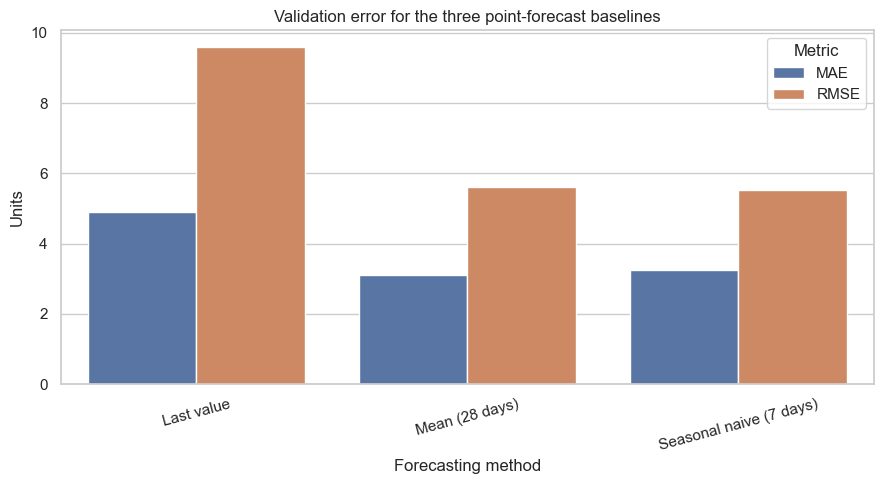

In [5]:
plot_metrics = overall_metrics.melt(
    id_vars="model",
    value_vars=["mae", "rmse"],
    var_name="metric",
    value_name="error",
)
plot_metrics["model"] = plot_metrics["model"].map({
    "last_value": "Last value",
    "seasonal_naive_7": "Seasonal naive (7 days)",
    "mean_28": "Mean (28 days)",
})
plot_metrics["metric"] = plot_metrics["metric"].str.upper()

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=plot_metrics, x="model", y="error", hue="metric", ax=ax)
ax.set(
    title="Validation error for the three point-forecast baselines",
    xlabel="Forecasting method",
    ylabel="Units",
)
ax.tick_params(axis="x", rotation=15)
ax.legend(title="Metric")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "baseline_validation_metrics.png", dpi=300, bbox_inches="tight")
plt.show()

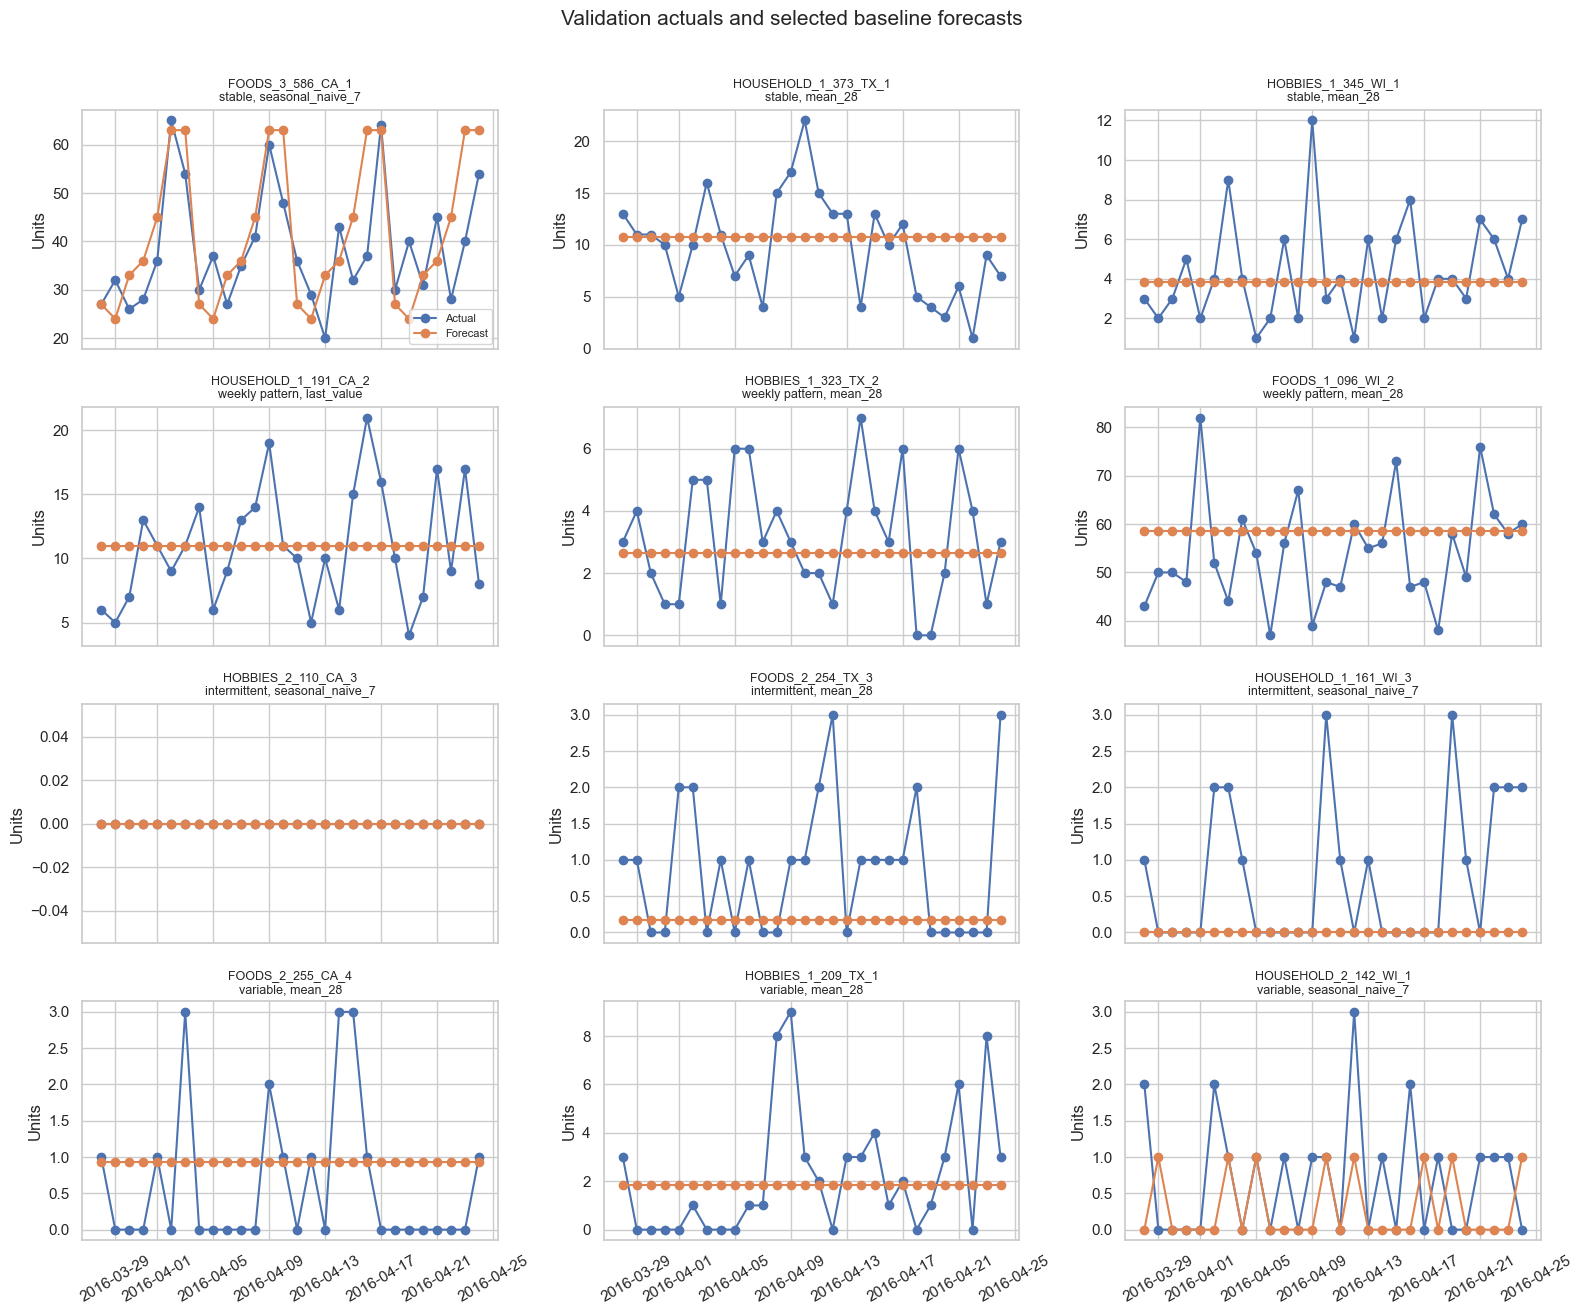

In [6]:
selected_forecasts = validation_forecasts[validation_forecasts["is_selected"]].copy()
validation_dates = (
    development[development["split"] == "validation"]
    .drop_duplicates("day_number")
    .set_index("day_number")["date"]
)
selected_forecasts["date"] = selected_forecasts["day_number"].map(validation_dates)

fig, axes = plt.subplots(4, 3, figsize=(16, 13), sharex=True)

for ax, series_key in zip(axes.flat, series_order):
    series_plot = selected_forecasts[selected_forecasts["series_key"] == series_key].sort_values("date")
    ax.plot(series_plot["date"], series_plot["actual"], marker="o", label="Actual")
    ax.plot(series_plot["date"], series_plot["forecast"], marker="o", label="Forecast")
    model = series_plot["selected_model"].iat[0]
    profile = series_plot["profile"].iat[0].replace("_", " ")
    ax.set_title(f"{series_key}\n{profile}, {model}", fontsize=9)
    ax.set_ylabel("Units")
    ax.tick_params(axis="x", rotation=30)

axes[0, 0].legend(fontsize=8)
fig.suptitle("Validation actuals and selected baseline forecasts", fontsize=15, y=1.01)
plt.tight_layout()
fig.savefig(FIGURE_DIR / "selected_validation_forecasts.png", dpi=300, bbox_inches="tight")
plt.show()

### Forecast interpretation

The series plots show where a metric summary can hide important behavior. Constant forecasts can follow the general level but miss weekly movement and isolated spikes. Seasonal naive forecasts preserve the latest weekday pattern but can repeat an unusual final week. Intermittent series contain many zero days, so occasional nonzero demand can dominate their errors.

These limitations motivate an uncertainty estimate around each point forecast. They do not justify choosing a more complex model until that model performs better on held-out data.

## 4. Save forecasting outputs

Notebook 05 will use the selected baseline for each series. The saved files contain validation predictions, model metrics, and the selected model list. Final-test sales are still absent.

In [7]:
forecasts_output = PROCESSED_DATA_DIR / "validation_point_forecasts.csv"
metrics_output = PROCESSED_DATA_DIR / "forecast_validation_metrics.csv"
selection_output = PROCESSED_DATA_DIR / "forecast_model_selection.csv"

validation_forecasts.to_csv(forecasts_output, index=False)
series_metrics.drop(columns=["mse", "tie_break_order"]).to_csv(metrics_output, index=False)
model_selection.to_csv(selection_output, index=False)

saved_outputs = pd.DataFrame(
    {
        "file": [forecasts_output.name, metrics_output.name, selection_output.name],
        "rows": [len(validation_forecasts), len(series_metrics), len(model_selection)],
        "size_kb": [
            round(forecasts_output.stat().st_size / 1024, 1),
            round(metrics_output.stat().st_size / 1024, 1),
            round(selection_output.stat().st_size / 1024, 1),
        ],
    }
)
display(saved_outputs)

assert validation_forecasts["day_number"].max() == VALIDATION_END
assert len(model_selection) == 12
print("Forecasting outputs saved without final-test data.")

,file,rows,size_kb
0,validation_point_forecasts.csv,1008,104.6
1,forecast_validation_metrics.csv,36,3.8
2,forecast_model_selection.csv,12,1.1


Forecasting outputs saved without final-test data.


## 5. Conclusion

Each selected series now has a documented point-forecast baseline chosen on the 28-day validation period. Notebook 05 will estimate seven-day forecast uncertainty from historical training errors and convert upper demand quantiles into safety-stock levels.

The final test period remains reserved for the completed forecasting and inventory workflow.